## Avvikanden

Ledningen önskar få svar på frågan: Eventuella avvikelser – något oväntat mönster som sticker ut?

Frågeställningen är hur jag kan nå fram till det som sticker ut. I min del av analysen kommer jag försöka hitta avvikande information. 

Jag kommer att börja med att ta fram kortfattad information av varje kategori.

Sedan kommer jag fokusera på följande:
- Tid
- Antal ordrar
- Städer
- Kategorier
- Omsättning

Med ovan nämnda fokusområden (samma som kategorierna i data) kommer jag ställa dem mot varandra och se om något sticker ut. Jag kommer fokusera på onormala toppar och bottnar.

Med hjälp av grafik och tabeller kommer jag visa det jag finner. Mina andra kollegors uppgifter kommer ge en kompletterande bild av hela data analysen.

I början behöver vi importera matplotlib och pandas. För att enkelt kunna tolka data genom grafik och i kodblock.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd


## Är datan komplett?

In [4]:
df = pd.read_csv("../data/ecommerce_sales.csv")
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.strftime("%Y-%m")

cities = df["city"].unique()
categories = df["category"].unique()

def max_revenue_category_city(df, city):
    return (
        df[df["city"] == city]
        .groupby("category")["revenue"]
        .max()
        .sort_values(ascending=False)
    )


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   order_id  2500 non-null   int64         
 1   date      2500 non-null   datetime64[us]
 2   city      2500 non-null   str           
 3   category  2500 non-null   str           
 4   price     2500 non-null   float64       
 5   units     2500 non-null   int64         
 6   revenue   2500 non-null   float64       
 7   month     2500 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 156.4 KB


Infon tog jag fram för att se om det fanns några problem med inläsningen av antalet ordrar under varje kategori. 

## Undersöka antal i varje kategori

In [5]:
df["city"].value_counts()

city
Stockholm    899
Göteborg     586
Malmö        396
Uppsala      381
Västerås     238
Name: count, dtype: int64

Visar antal ordrar från varje stad. Visar på att Stockholm har betydligt fler än resterande städer.

In [6]:
df["category"].value_counts()


category
Electronics    618
Clothing       509
Home           490
Sports         415
Beauty         241
Toys           227
Name: count, dtype: int64

Visar antal ordrar under varje kategori. Detta visar på vilken kategori som har flest ordrar från samtliga städer. Ger en generell bild på hur köp mönstret varit utspritt.

In [7]:
df["price"].value_counts()


price
50.00     74
628.23     2
339.73     2
912.30     2
236.11     2
          ..
219.58     1
134.86     1
546.50     1
646.99     1
473.83     1
Name: count, Length: 2401, dtype: int64

Sorterar på ordrar och pris, stycke pris per produkt på order. Inte slutsumma eller vad som köpts utan bara att summan förekommit på x antal ordrar. Detta visar på vilken summa som är vanligast. 

Tabellen visar att priset 50kr är överrepresenterad. Detta kommer jag undersöka vidare i analysen nedan.

In [8]:
df["units"].value_counts()

units
3    666
2    639
4    448
1    381
5    230
6     96
7     33
8      6
9      1
Name: count, dtype: int64

Tabellen visar hur många ordrar som har vilket antal produkter. Detta visar det vanligaste och ovanligaste kvittot. Vanligast är ex att det säljs 3 produkter per order. 

In [9]:
df["revenue"].value_counts()

revenue
100.00     20
200.00     19
150.00     17
50.00       9
250.00      3
           ..
439.16      1
674.30      1
1093.00     1
2587.96     1
1421.49     1
Name: count, Length: 2413, dtype: int64

Tabellen visar vilket totalbelopp som är vanligast på ordrarna. Det är 20 ordrar som har totalbelopp 100kr vilket är det som är vanligast. Hämtat från samtliga städer.

In [10]:
df["date"].value_counts()

date
2024-01-04    23
2024-04-09    22
2024-06-06    22
2024-05-10    22
2024-06-07    21
              ..
2024-05-12     7
2024-02-05     7
2024-03-20     7
2024-02-11     6
2024-02-24     6
Name: count, Length: 182, dtype: int64

Tabellen sammanfattar antal ordrar på vilket datum och sorterar på vilket datum som har flest ordrar registrerade för alla städer. 

Ovan har jag tagit fram antal från varje kategori. Nedan kommer jag att försöka förtydliga och tolka vad det betyder.

## Vad säljs, när och hur mycket

In [11]:
# vad har sålts i varje stad, när och hur mycket.

def show_month_categories_city(df, month):

    month_names = {
        "2024-01": "January 2024",
        "2024-02": "February 2024",
        "2024-03": "March 2024",
        "2024-04": "April 2024",
        "2024-05": "May 2024",
        "2024-06": "June 2024",
        }

    month_data = (
        df[df["month"] == month]
        .groupby(["city", "category"])["units"]
        .sum()
        .reset_index()
    )

    visning = month_data.pivot(
        index="category", 
        columns="city", 
        values="units"
    )

    print(f"{month_names[month]} Sales by City and Category")
    print(visning)



In [43]:
show_month_categories_city(df, "2024-01")

home_vasteras_period = df[
    (df["city"] == "Västerås") &
    (df["category"] == "Home")
]

home_vasteras_summ = home_vasteras_period.groupby(
    home_vasteras_period["date"].dt.to_period("M"))["units"].sum()

print("\nVästerås home kategori försäljningantal:\n", home_vasteras_summ)

January 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty             38     28         35       22        15
Clothing           69     55         90       57        25
Electronics       102     82        144       69        27
Home               49     28         60       34         7
Sports             53     24         87       22        29
Toys               23     18         24       22        15

Västerås home kategori försäljningantal:
 date
2024-01     7
2024-02    19
2024-03    12
2024-04    28
2024-05    29
2024-06    14
Freq: M, Name: units, dtype: int64


Inga specifika annomaliteter i data. Bara att vi ser att västerås har få ordrar i home kategorin. 

När jag har kollat på hela perioden anser jag att den låga försäljningen för home i Västerås inte är speciellt lågt jämfört med övriga månader. De har inte hög försäljning på home i januari, mars och juni. Eftersom data perioden enbart sträcker sig över 6 månader kan vi inte säkerställa att den låga försäljningen är ovanligt. Därav kommer jag inte att kolla vidare på detta.

In [13]:
show_month_categories_city(df, "2024-02")

February 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty           16.0    8.0       24.0     11.0       9.0
Clothing         50.0   40.0       79.0     35.0      14.0
Electronics      99.0   72.0      126.0     64.0      33.0
Home             50.0   40.0       48.0      7.0      19.0
Sports           32.0   29.0       58.0     19.0       NaN
Toys             28.0   11.0       45.0     16.0      15.0


In [14]:
show_month_categories_city(df, "2024-03")

March 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty             35      8         57       19         3
Clothing           22     27         86       43        44
Electronics        62     38         78       29        17
Home               65     40         56       36        12
Sports             21     39         84       34        24
Toys               24     18         71       17         7


In [15]:
show_month_categories_city(df, "2024-04")

April 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty             15      6         45        7        17
Clothing           88     45         98       49        53
Electronics        48     44         72       42         9
Home               61     24        101       25        28
Sports             84     47        114       31         4
Toys               30     21         58       20        19


In [16]:
show_month_categories_city(df, "2024-05")

May 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty           26.0   32.0       26.0     14.0      17.0
Clothing         65.0   37.0      116.0     78.0      44.0
Electronics      47.0   49.0       93.0     42.0      18.0
Home             78.0   50.0       83.0     37.0      29.0
Sports           91.0   48.0      112.0     27.0      12.0
Toys             27.0   19.0       25.0     25.0       NaN


In [17]:
show_month_categories_city(df, "2024-06")

June 2024 Sales by City and Category
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty             32     13         36       26        19
Clothing           44     24        105       41        32
Electronics        67     28         86       47        19
Home               61     33         71       32        14
Sports             60     60         84       45        27
Toys               26     26         42       21         4


Här har jag kollat på månad för månad hur antalet ordar har spridit ut sig. Här visar sig att jag har några NAN värden som behöver analyseras vidare. Det gör jag nedan.

## Undersöka NAN värde

In [44]:
#upptäckt nan i datan ovan specificerar här

df.isna().sum() #ger resultat 0 på samtliga så det är komplett på kategorierna från org data
print(f"Kollar efter saknat värde i datasettet: {df.isna().sum().sum()}, ser inte ut som att det saknas värden i data settet, men har fått nan i följande:")

def nan_vasteros(df):
    sports_feb = df[
        (df["month"] == "2024-02") &
        (df["city"] == "Västerås") &
        (df["category"] == "Sports")
    ]

    if sports_feb.empty:
        print("Ingen data för Sport i Västerås februari 2024.")
    else:
        print("Det finns data för Sport Västerås februari 2024.")

    toys_may= df[
        (df["month"] == "2024-05") &
        (df["city"] == "Västerås") &
        (df["category"] == "Toys")
    ]

    if toys_may.empty:
        print("Ingen data för Toys i Västerås maj 2024.")
    else:
        print("Det finns data för Toys västerås maj 2024.")

print("Försäljning i dessa kategorier:", nan_vasteros(df))

Kollar efter saknat värde i datasettet: 0, ser inte ut som att det saknas värden i data settet, men har fått nan i följande:
Ingen data för Sport i Västerås februari 2024.
Ingen data för Toys i Västerås maj 2024.
Försäljning i dessa kategorier: None


In [45]:
#då ovan bara visar att det saknas försäljning över en hel månad under dessa kategorier i västerås, vill jag ta reda på om det är hela månaden eller någon specifik dag som saknas.

sports_feb_days = df[
    (df["month"] == "2024-02") &
    (df["city"] == "Västerås") &
    (df["category"] == "Sports")
]

toys_may_days = df[
    (df["month"] == "2024-05") &
    (df["city"] == "Västerås") &
    (df["category"] == "Toys")
]


print("Kontrollerar för saknad försäljning på daglig basis i februari 2024 inom kategorin Sport i Västerås:")
print(sports_feb_days[["date", "units"]].sort_values("date"))

print("\nKontrollerar för saknad försäljning på daglig basis i maj 2024 inom kategorin Toys i Västerås:")
print(toys_may_days[["date", "units"]].sort_values("date"))

Kontrollerar för saknad försäljning på daglig basis i februari 2024 inom kategorin Sport i Västerås:
Empty DataFrame
Columns: [date, units]
Index: []

Kontrollerar för saknad försäljning på daglig basis i maj 2024 inom kategorin Toys i Västerås:
Empty DataFrame
Columns: [date, units]
Index: []


Ovan resultat visar att det inte finns någon registrerad försäljning alls under sports och toys i västerås under hela månadern februari och maj. Första delen kollar om det finns värden i hela månaden, det fanns det ej, andra delen kollar om det var specifika dagar som saknar försäljning. Så var inte fallet, hela månaderna saknar registrerad försäljning för dessa kategorierna. 

Förr att visa det tydligare kommer jag visa vilka månader som västerås faktiskt har försäljning på dessa kategorier.
Det är alltså inte någon enstaka dag som saknar försäljning utan hela månaden. 

In [46]:
#visa vilka månader som faktiskt har försäljning för sports och toys för västerås. om månad 2 och 5 saknas så är det hela månaden som saknas. 

months_with_sales_sports = sorted(
    df[
        (df["city"] == "Västerås") &
        (df["category"] == "Sports")
    ]["month"].unique()
)

print("Månader med försäljning för kategorin sport i Västerås:")
print(months_with_sales_sports)

months_with_sales_toys = sorted(
    df[
        (df["city"] == "Västerås") &
        (df["category"] == "Toys")
    ]["month"].unique()
)

print("Månader med försäljning för kategorin toys i Västerås:")
print(months_with_sales_toys)


Månader med försäljning för kategorin sport i Västerås:
['2024-01', '2024-03', '2024-04', '2024-05', '2024-06']
Månader med försäljning för kategorin toys i Västerås:
['2024-01', '2024-02', '2024-03', '2024-04', '2024-06']


Resultatet visar att det är månaderna 1,3,4,5 och 6 som har försäljning av sports. månad 2 (februari) saknar alltså försäljning för kategorin sports i västerås

Resultatet visar att månaderna: 1,2,3,4 och 6 har försäljning av toys. Månad 5 (maj) saknar alltså försäljning för kategorin toys i västerås


Nu när jag har hanterat Nan värderna kommer jag fortsätta att undersöka om det är någon försäljning som är ovanlig på något sätt.

## Undersöka intjän

In [47]:
#Jag vill börja med att undersöka högsta revenue per stad under hela perioden. För att sedan jämföra mellan städerna och sedan vad som skiljer dem mer.

max_revenue_per_city = df.loc[
    df.groupby("city")["revenue"].idxmax(),
    ["city", "category", "revenue"]
].sort_values("revenue",ascending=False)

print("Max intjän per stad:")
print(max_revenue_per_city)

Max intjän per stad:
           city     category  revenue
1411  Stockholm  Electronics  9192.60
1339   Göteborg  Electronics  8516.85
1491   Västerås  Electronics  8370.12
1733    Uppsala  Electronics  7366.38
2282      Malmö       Sports  6293.34


Här ser vi att Malmö skiljer deras högsta revenue kategori är Sports medans resten av städerna är Electronics. Vilket gör det intressant att undersöka vad Malmö har för högsta revenue i övriga kategorier.

In [48]:
#Malmös högsta revenue i alla kategorier.

malmo_max_revenue = (
    df[df["city"] == "Malmö"]
    .groupby("category")["revenue"]
    .max()
    .sort_values(ascending=False)
)

print("Max intjän i Malmö per kategori:")
print(malmo_max_revenue)

Max intjän i Malmö per kategori:
category
Sports         6293.34
Electronics    6260.58
Clothing       3226.80
Home           3159.80
Toys           1845.13
Beauty         1579.83
Name: revenue, dtype: float64


Här ser vi att Sports tog första platsen med liten marginal vilket gör det intressant att fortsätta att kolla på andra städers max revenue i alla kategorier och se om deras sports ligger som nr två eller hur de skiljer sig.

In [50]:
#Undersöka vilka kategorier i alla andra städer som har högsta revenue och jämföra med malmö.
city_max_revenue = []

for city in cities:
    if city != "Malmö":
        max_revenue_category = max_revenue_category_city(df, city)
        max_revenue_category.name = city
        city_max_revenue.append(max_revenue_category)

compare_max_revenue = pd.concat(city_max_revenue, axis=1)
print("\nJämförelse av max intjän per kategori i övriga städer")
print(compare_max_revenue)


Jämförelse av max intjän per kategori i övriga städer
             Stockholm  Uppsala  Göteborg  Västerås
category                                           
Electronics    9192.60  7366.38   8516.85   8370.12
Sports         5628.18  5598.06   5455.38   6312.48
Clothing       4634.56  5480.24   3516.60   3795.40
Toys           3511.62  1532.00   1980.72   1842.70
Home           3123.24  3640.45   3926.40   3005.52
Beauty         2675.80  2497.64   2473.02   2315.65


Här ser vi att kategorin sports är nummer 2 i samtliga andra städer förutom i malmö då den var nr 1. Electronics ligger överst för alla städer förutom malmö. 

Malmös övriga kategorier skiljer sig ytterligare på kategorierna toys och home som byter plats jämfört med resterande städer. 

Malmös handlingsmönster är alltså lite annorlunda än resterande städer. 

Frågan som jag nu ställer mig är det en specifik månad som samtliga högsta revenues uppstår i eller är de olika för olika städer?

In [51]:
#undersöka när högsta revenue inträffar för samtliga städer

max_revenue_months = df.loc[
    df.groupby("city")["revenue"].idxmax(),
    ["city", "category", "revenue", "month"]
].sort_values("revenue", ascending=False)

print("Månader med max intjän uppstod i alla städer:")
print(max_revenue_months)

Månader med max intjän uppstod i alla städer:
           city     category  revenue    month
1411  Stockholm  Electronics  9192.60  2024-02
1339   Göteborg  Electronics  8516.85  2024-02
1491   Västerås  Electronics  8370.12  2024-06
1733    Uppsala  Electronics  7366.38  2024-06
2282      Malmö       Sports  6293.34  2024-06


Intressant att februari och juni sticker ut som de månaderna som högsta revenue inträffade på. Stockholm och Göteborgs sålde högst i februari och övriga städer i juni. 

Då ställer jag mig frågan hur såg stockholm och göteborg ut i juni samt hur såg övriga städer ut i februari.

In [52]:
#Undersöka hur februari såg ut för västerås, uppsala och malmö. hur juni såg ut för stockholm och göteborg.

max_revenue_february_three_cities = df.loc[
    df[
        (df["month"] == "2024-02") &    
        (df["city"].isin(["Västerås", "Uppsala", "Malmö"]))
    ]
    .groupby("city")["revenue"]
    .idxmax()
]

print("Max intjän i februari 2024 för Västerås, Uppsala och Malmö:")
print(max_revenue_february_three_cities)

Max intjän i februari 2024 för Västerås, Uppsala och Malmö:
      order_id       date      city     category    price  units  revenue  \
770     100770 2024-02-23     Malmö  Electronics  1169.44      5  5847.20   
116     100116 2024-02-10   Uppsala  Electronics  1593.28      4  6373.12   
1508    101508 2024-02-06  Västerås  Electronics   750.75      5  3753.75   

        month  
770   2024-02  
116   2024-02  
1508  2024-02  


Februari är alltså den månad som electronics har högst revenue i samtliga städer. 

Hur ser nu juni ut?

In [53]:
max_revenue_juni_two_cities = df.loc[
    df[
        (df["month"] == "2024-06") &
        (df["city"].isin(["Stockholm", "Göteborg"]))
    ]
    .groupby("city")["revenue"]
    .idxmax()
]

print("Max intjän i juni 2024 för Göteborg och Stockholm")
print(max_revenue_juni_two_cities)

Max intjän i juni 2024 för Göteborg och Stockholm
      order_id       date       city     category    price  units  revenue  \
1061    101061 2024-06-09   Göteborg  Electronics  1460.44      4  5841.76   
233     100233 2024-06-17  Stockholm       Sports   675.64      6  4053.84   

        month  
1061  2024-06  
233   2024-06  


Juni har Uppsala och Göteborg högst revenue för electrolics. Stockholm och Malmö har sports som högst i juni.

Nu ställer jag mig frågan när är vilken kategori top 1 i revenue, är det samma för hela perioden eller skiljer det sig?

In [55]:
# undersöka om någon kategori dominerar hela perioden i någon stad eller om det är olika hela tiden.

monthly_top_revenue = df.loc[
    df.groupby(["city", "month"])["revenue"].idxmax(),
    ["city", "month", "category"]
]

top_winners_tab = {}

for city in monthly_top_revenue["city"].unique():

    city_data = monthly_top_revenue[
        monthly_top_revenue["city"] == city
        ]

    category_months = {}

    for category in city_data["category"].unique():
        months = sorted(
            city_data[
            city_data["category"] == category
            ]["month"]
            .str[-2:]
            .astype(int)
            .tolist()
            
        )
        def format_months(months):

            if months == list(range(min(months), max(months) + 1)):
                return f"{min(months)}-{max(months)}"

            return ",".join(map(str, months))

        category_months[category] = format_months(months)
        top_winners_tab[city] = pd.Series(category_months)

compare_top_winners = pd.DataFrame(top_winners_tab)
compare_top_winners = compare_top_winners.fillna("")

print("Jämförelse av vilka månader som högsta intjän per kategori skedde:")
print(compare_top_winners)

Jämförelse av vilka månader som högsta intjän per kategori skedde:
            Göteborg Malmö Stockholm Uppsala Västerås
Electronics      1-6   1-5   1,2,3,5     1-6  1,2,4,6
Home                                              3,5
Sports                 6-6       4,6                 


Här ser vi att Malmös högsta revenue var en engångsföreteelse. I övriga månader är electronics den högsta inkomstkällan.

Nu har jag specificerat när de största revenue topparna har hänt och från var. 
Nu ställer jag mig frågan:

När jag vet topparna, vad är egenligen medelköpet i respektive stad och kategori, något som sticker ut där?

## Undersökning av median

In [56]:
#hitta medianen för samtliga städer och kategorier för att se om det finns några avvikelser.

city_median_revenue = (
    df.groupby(["city", "category"])["revenue"]
    .median()
    .unstack()
)

print("Jämförelse av median intjän per kategori i samtliga städer:")
print(city_median_revenue)

Jämförelse av median intjän per kategori i samtliga städer:
category    Beauty  Clothing  Electronics    Home    Sports    Toys
city                                                               
Göteborg   719.645  1108.790     1944.920  855.79  1933.880  588.29
Malmö      606.740   991.980     2061.395  970.71  1474.370  453.90
Stockholm  532.160  1055.640     1768.590  857.79  1519.950  525.48
Uppsala    639.560  1004.385     2000.120  912.30  1434.965  514.19
Västerås   492.840   885.140     1550.805  980.12  1440.080  514.16


Intressant med det här är att Malmös högsta revenue totalt är i sports men högsta median är i electronics.

In [57]:
monthly_median_revenue = (
    df.groupby(["city", "month", "category"])["revenue"]
    .median()
    .reset_index()
)

monthly_top_median = monthly_median_revenue.loc[
    monthly_median_revenue.groupby(
        ["city", "month"]
    )["revenue"].idxmax()
]

top_median_tab = {}

for city in monthly_median_revenue["city"].unique():

    city_data = monthly_top_median[
        monthly_top_median["city"] == city
        ]

    category_months = {}

    for category in city_data["category"].unique():
        months = sorted(
            city_data[
            city_data["category"] == category
            ]["month"]
            .str[-2:]
            .astype(int)
            .tolist()
            
        )
        def format_months(months):

            if months == list(range(min(months), max(months) + 1)):
                return f"{min(months)}-{max(months)}"

            return ",".join(map(str, months))

        category_months[category] = format_months(months)
        top_median_tab[city] = pd.Series(category_months)

compare_median_winners = pd.DataFrame(top_median_tab)
compare_median_winners = compare_median_winners.fillna("")

print("Jämförelse när median intjän per kategori och stad skedde:")
print(compare_median_winners)

Jämförelse när median intjän per kategori och stad skedde:
            Göteborg Malmö Stockholm Uppsala Västerås
Clothing                                          4-4
Electronics      1-3   1-3   1,2,3,6   1,2,4      1-3
Sports           4-6   4-6       4-5   3,5,6      5-6


Här ser vi något som sticker ut. Clothing har aldrig varit nämnt på revenu lista någonstans. Ändå är det högst medelvärde på den kategorin i april för västerås. 

Övriga månader ser vi fortsatt electronics och sport som dominerar både top revenue och median revenue. 

Nu ställer jag mig frågan:
Hur såg april ut för västerås i resterande kategorier?


In [58]:
#ta fram median och top för västerås i april

vasteras_april_med_max = (
    df[
        (df["city"] == "Västerås") &
        (df["month"] == "2024-04")
    ]
    .groupby("category")
    .agg(
        Median = ("revenue", "median"),
        Max =  ("revenue", "max"),
        Units = ("units", "sum"),
        Orders = ("order_id", "count")
        )
    .sort_values("Median", ascending=False)
)

print("Median och max intjän i Västerås för april 2024 per kategori:")
print(vasteras_april_med_max)

Median och max intjän i Västerås för april 2024 per kategori:
               Median      Max  Units  Orders
category                                     
Clothing     1202.900  2568.96     53      15
Electronics  1188.840  5175.36      9       5
Sports        980.600   980.60      4       1
Home          876.540  3005.52     28      11
Beauty        492.840  1713.55     17       7
Toys          467.835  1292.60     19       6


Här ser vi att högsta enskilda köpen ligger under electronics och home. Men att det största antalet ordrar och varor hamnar under clothing vilket gör att totala medelvärdet blir högre. 

Jag ställer mig nu frågan:
Är clothing alltid den kategori med flest orders och units eller är detta ett enstaka fall?

## Undersöka avvikande kategori Clothing

In [60]:
#Tabeller för antal orders och units för samtliga städer och kategorier under hela perioden.

units_pivot = (
    df.groupby(["category", "city"])
    ["units"]
    .sum()
    .unstack()
)

orders_pivot = (
    df.groupby(["category", "city"])
    ["order_id"]
    .count()
    .unstack()
)

print("Totala antal produkter per stad och kategori:")
print(units_pivot)

print("\nTotala antal ordrar per stad och kategori:")
print(orders_pivot)

Totala antal produkter per stad och kategori:
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty            162     95        223       99        80
Clothing          338    228        574      303       212
Electronics       425    313        599      293       123
Home              364    215        419      171       109
Sports            341    247        539      178        96
Toys              158    113        265      121        60

Totala antal ordrar per stad och kategori:
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty             56     31         86       37        31
Clothing          104     69        181       86        69
Electronics       145    104        220      101        48
Home              136     83        163       65        43
Sports             91     70        169       56        29
Toys               54    

För västerås är clothing den kategori som flest köper och med störst antal. Under april månad tog västerås in en stor del av totala andelen ordrar men bara en liten del av antal produkter.

Ser vi på hela perioden och alla städer så är clothing INTE en kategori som sticker ut vad gäller antal ordrar eller produkter. Den är med i toppen för västerås men varierar jämfört med resterande städer.

Att västerås fick en topp med clothing i april anses vara ett engångsfall.

När jag skummar igenom datan längst upp så ser jag att västerås har tendens att ha lågt antal försäljning återkommande på nästan alla månader och olika kategorier.

Men när jag kollar på Uppsala och kategorien Home så är det enbart 1 månad (februari) som är lägre än normalt.
Det ska jag kolla på nu.

## Undersöka Home i Uppsala

In [62]:
#Undersöka det låga värdet i home februari i uppsala.

uppsala_min_home_feb = df[
    (df["city"] == "Uppsala") &
    (df["category"] == "Home") &
    (df["month"] == "2024-02")
]
   
print(uppsala_min_home_feb)

      order_id       date     city category   price  units  revenue    month
77      100077 2024-02-21  Uppsala     Home  313.97      2   627.94  2024-02
607     100607 2024-02-08  Uppsala     Home  508.76      1   508.76  2024-02
634     100634 2024-02-03  Uppsala     Home  643.84      3  1931.52  2024-02
1000    101000 2024-02-13  Uppsala     Home  361.08      1   361.08  2024-02


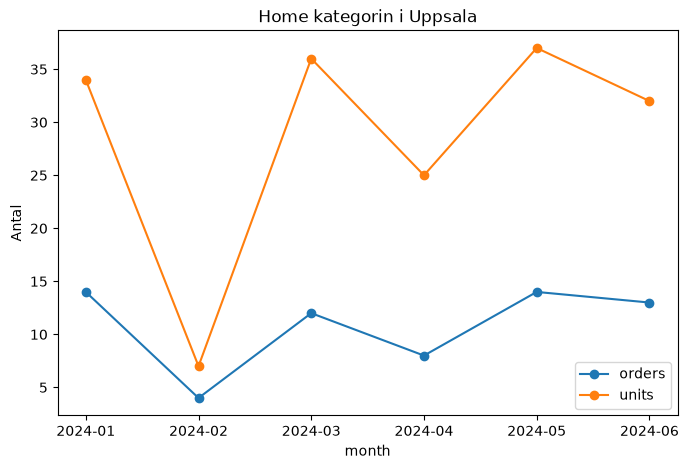

In [33]:
uppsala_home_units_orders = (
    df[
        (df["city"] == "Uppsala") &
        (df["category"] == "Home")
    ]
    .groupby("month")
    .agg(
        orders = ("order_id", "count"),
        units = ("units", "sum")
    )
)


uppsala_home_units_orders.plot(
    y = ["orders", "units"],
    marker = "o",
    figsize = (8, 5)
)

plt.title("Home kategorin i Uppsala")
plt.ylabel("Antal")
plt.show()

Här ser vi mer tydligt det jag upptäckte tidigare att antalet försäljning sjönk onormalt för februari.

Men grafiken visar att orders bara ligger lite under normalt medans antalet units är mycket lägre än normalt.

## Summan 50

Från toppen har det visats att det finns 74st ordrar med summan 50. Samtliga andra ordrar är annan summa. 

74 är alltså överrepresenterat. Nu vill jag undersöka var det kommer från.

Men det betyder inte att order totalt är 50kr utan bara att något har registrerats på ordern som kostat 50kr. 
Det kan visa på merförsäljning eller liknande. 

Därför vill jag se om någon stad har fler 50kr registreringar än andra.

In [63]:
#Undersöka var summan 50 kommer från
price_50 = df[df["price"] == 50]

price_50_where_piv = pd.crosstab(
    price_50["category"],
    price_50["city"]
)

print("Sorterat på stad och kategori var 50kr registreringarna görs:")
print(price_50_where_piv)

print("\nTotalt per stad:")
print(price_50_where_piv.sum())

Sorterat på stad och kategori var 50kr registreringarna görs:
city         Göteborg  Malmö  Stockholm  Uppsala  Västerås
category                                                  
Beauty              2      1          2        1         1
Clothing            2      2          1        4         1
Electronics         4      5          4        3         1
Home                5      2          5        3         1
Sports              1      1          4        0         0
Toys                0      5          7        4         2

Totalt per stad:
city
Göteborg     14
Malmö        16
Stockholm    23
Uppsala      15
Västerås      6
dtype: int64


I tabellerna ovan ser vi att summan 50kr dyker upp flest gånger i Stockholm sedan Malmö och Västerås har minst antal registreringar. Med hjälp av detta kan ledningen se vilka kategorier som har störst utvecklingsmöjlihget för merförsäljning. 

## Sammanfattning

Det vi ser på denna period är att det har förekommit flera avvikande händelser. Om det är ett återkommande mönster eller av vilka anledningar dessa avvikanden uppstår kan vi inte klargöra pga vi har bara data från 5 städer under 6 månader. För att få en helhetsbild behöver vi åtmindstonde se på ett helt år för att kunna se större mönster. Först efter att vi har klargjort helårs mönster kan vi börja generalisera och kolla på kortare perioder. 

Den data vi har utgått från räcker dock för att se förbättringsområden. Vad som skulle vara intressant framåt är att undersöka rea perioder, kampanjer mm om det är något som har påverkan på dessa mönster som uppstått i min undersökning. 

## Vad ska ledningen ta med sig?

Västerås förekommer ofta i denna undersökning vilket kan tyda på behov av utbildning, satsa på marknadsföring i den staden och försöka göra marknadsundersökningar för att hitta försäljnings mönster i Västerås. 

Stockholm har kontinuerligt höga antal registreringar och verkar tuffa på bra. Här behöver andra variablar undersökas för att se förbättningsmöjligheter. 

Övriga städer svajar lite upp och ned i olika kategorier. Det kan vara säsongsbaserat, kampanj baserat eller andra mjuka anledningar (ex sjukdommar mm). Det är även här intressant att fortsätta undersöka fler variablar. 

Denna rapport genomfördes av Mattias Andersson. 